**Aim:** Preprocessing scRNA-seq datasets

**Tools**: 
- [`scanpy`](https://scanpy.readthedocs.io/en/stable/)

Tasks:
- [X] Load `adata` objects and merge them into one big dataset
- [ ] Data cleaning
    - Initially, we have seen we need to find more dead cells!
    - Run Scrublet with `batch_key='batch'` option. 

In [1]:
import os, sys
import pickle
import numpy as np 
import pandas as pd
from glob import glob

import scanpy as sc
import scanpy.external as sce
import anndata as ad
import scvi

import seaborn as sns
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import pyplot as plot
from matplotlib.backends.backend_pdf import PdfPages

sc.settings.verbosity = 1             # verbosity: errors (0), warnings (1), info (2), hints (3)
sc.settings.set_figure_params(dpi=300, frameon=False, figsize=(5, 5), facecolor='white')

sc.logging.print_header()

scanpy==1.9.1 anndata==0.7.6 umap==0.5.1 numpy==1.20.3 scipy==1.7.1 pandas==1.3.3 scikit-learn==1.0 statsmodels==0.13.0 python-igraph==0.9.8 pynndescent==0.5.4


In [2]:
# https://stackoverflow.com/questions/21884271/warning-about-too-many-open-figures
plt.rcParams.update({'figure.max_open_warning': 0})

plt.close('all')

In [3]:
# https://www.techcoil.com/blog/how-to-save-and-load-objects-to-and-from-file-in-python-via-facilities-from-the-pickle-module/

def save_obj(obj, name ):
    with open(name, 'wb') as f:
        pickle.dump(obj, f, pickle.HIGHEST_PROTOCOL)

def load_obj(name ):
    with open(name, 'rb') as f:
        return pickle.load(f)

In [4]:
mkdir -pv figures

### Load `cellranger` results and label samples

<!-- https://www.kallistobus.tools/tutorials/kb_aggregate/python/kb_aggregating_count_matrices.html -->



In [5]:
%%time 
data = {}
for file in sorted(glob('counts/*/outs/filtered_feature_bc_matrix.h5')):
    sample = file.split('/')[1].replace('-','')
    print (sample, file)
    
    adata = sc.read_10x_h5(file)#, gex_only=False)
    
    data[sample] = adata
    del adata
    print ('_'*50)


MDMAMale counts/MDMA-Male/outs/filtered_feature_bc_matrix.h5


Variable names are not unique. To make them unique, call `.var_names_make_unique`.
Variable names are not unique. To make them unique, call `.var_names_make_unique`.


__________________________________________________
MDMA_acute_female_011221 counts/MDMA_acute_female_011221/outs/filtered_feature_bc_matrix.h5


Variable names are not unique. To make them unique, call `.var_names_make_unique`.
Variable names are not unique. To make them unique, call `.var_names_make_unique`.


__________________________________________________
MDMA_acute_female_100121 counts/MDMA_acute_female_100121/outs/filtered_feature_bc_matrix.h5


Variable names are not unique. To make them unique, call `.var_names_make_unique`.
Variable names are not unique. To make them unique, call `.var_names_make_unique`.


... (13 outputs left out)

Variable names are not unique. To make them unique, call `.var_names_make_unique`.
Variable names are not unique. To make them unique, call `.var_names_make_unique`.


__________________________________________________
Saline_202110 counts/Saline_202110/outs/filtered_feature_bc_matrix.h5


Variable names are not unique. To make them unique, call `.var_names_make_unique`.
Variable names are not unique. To make them unique, call `.var_names_make_unique`.


__________________________________________________
CPU times: user 4.13 s, sys: 1.27 s, total: 5.4 s
Wall time: 5.43 s


In [6]:
!mkdir -pv preprocessing

In [7]:
name = 'preprocessing/adatas-raw.pkl'

save_obj(data, name)

In [8]:
ls -s --block-size=M preprocessing/adatas-raw.pkl

899M preprocessing/adatas-raw.pkl


___


In [9]:
name = 'preprocessing/adatas-raw.pkl'
data = load_obj(name)

In [10]:
new_keys = [
    'MDMA_male_1',
    'MDMA_acute_female_1',
    'MDMA_acute_female_2',
    'MDMA_acute_female_3',
    'MDMA_acute_male_1',
    'MDMA_acute_male_2',
    'MDMA_acute_male_3',

    'MDMA_male_2',
    'MDMA_male_3',
    
    'Meth_male_1',
    'Meth_male_2',
    'Meth_male_3',
    
    'Saline_male_1',
    'Saline_male_2',
    'Saline_male_3'
]

In [11]:
def rename(d, new_keys):
    """
    https://stackoverflow.com/questions/16475384/rename-a-dictionary-key
    """
    new_dict = {}
    for key, new_key in zip(d.keys(), new_keys):
        new_dict[new_key] = d[key]
        print(f'{new_key} <- {key}')
        
    return new_dict

In [12]:
data = rename(data,new_keys)

MDMA_male_1 <- MDMAMale
MDMA_acute_female_1 <- MDMA_acute_female_011221
MDMA_acute_female_2 <- MDMA_acute_female_100121
MDMA_acute_female_3 <- MDMA_acute_female_180921
MDMA_acute_male_1 <- MDMA_acute_male
MDMA_acute_male_2 <- MDMA_acute_male_021221_1
MDMA_acute_male_3 <- MDMA_acute_male_021221_2
MDMA_male_2 <- MDMA_male_093021
MDMA_male_3 <- MDMA_male_100121
Meth_male_1 <- Meth
Meth_male_2 <- Meth_093021
Meth_male_3 <- Meth_100121
Saline_male_1 <- SalineMale
Saline_male_2 <- Saline_093021
Saline_male_3 <- Saline_202110


### Merge datasets

In [13]:
EXPs = []
OBSs = []
for sample in data:
    
    print (sample)
    exp = data[sample].copy()
    exp.obs['batch'] = sample
    EXPs.append(exp.to_df())
    OBSs.append(exp.obs)
    
    # del exp 

Variable names are not unique. To make them unique, call `.var_names_make_unique`.
Variable names are not unique. To make them unique, call `.var_names_make_unique`.
Variable names are not unique. To make them unique, call `.var_names_make_unique`.
Variable names are not unique. To make them unique, call `.var_names_make_unique`.
Variable names are not unique. To make them unique, call `.var_names_make_unique`.


MDMA_male_1
MDMA_acute_female_1
MDMA_acute_female_2
MDMA_acute_female_3
MDMA_acute_male_1


Variable names are not unique. To make them unique, call `.var_names_make_unique`.


MDMA_acute_male_2


Variable names are not unique. To make them unique, call `.var_names_make_unique`.
Variable names are not unique. To make them unique, call `.var_names_make_unique`.


MDMA_acute_male_3
MDMA_male_2


... (2 outputs left out)

Variable names are not unique. To make them unique, call `.var_names_make_unique`.
Variable names are not unique. To make them unique, call `.var_names_make_unique`.
Variable names are not unique. To make them unique, call `.var_names_make_unique`.
Variable names are not unique. To make them unique, call `.var_names_make_unique`.


Meth_male_2
Meth_male_3
Saline_male_1
Saline_male_2


Variable names are not unique. To make them unique, call `.var_names_make_unique`.


Saline_male_3


In [14]:
adata = ad.AnnData(
    X=pd.concat(EXPs),obs=pd.concat(OBSs)
)

Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
Variable names are not unique. To make them unique, call `.var_names_make_unique`.


In [15]:
adata.obs['cond'] = adata.obs['batch'].str[:-2]

In [16]:
for c in set(adata.obs['cond']): print(c)

MDMA_acute_male
Saline_male
MDMA_acute_female
Meth_male
MDMA_male


In [17]:
adata.obs['group'] = adata.obs.cond.str.split('_').str[0]

In [18]:
for c in set(adata.obs['group']): print(c)

Meth
Saline
MDMA


### Data cleaning

Filtering cells with high mitochondrial gene counts
- https://www.biostars.org/p/347428/
- https://github.com/theislab/scanpy/issues/639

More Filtering!
- https://nbisweden.github.io/workshop-scRNAseq/labs/compiled/scanpy/scanpy_01_qc.html
> _A standard approach is to filter cells with low amount of reads as well as genes that are present in at least a certain amount of cells. Here we will only consider cells with at least 200 detected genes and genes need to be expressed in at least 3 cells. Please note that those values are highly dependent on the library preparation method used._

In [19]:
adata0 = adata.copy()

Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
Variable names are not unique. To make them unique, call `.var_names_make_unique`.


#### QC Evaluation

In [20]:
adata_qc = adata0.copy()

Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
Variable names are not unique. To make them unique, call `.var_names_make_unique`.


In [21]:
adata_qc.var_names_make_unique()

# mitochondrial genes
adata_qc.var['mt'] = adata_qc.var_names.str.startswith('mt-')  # annotate the group of mitochondrial genes as 'mt'
sc.pp.calculate_qc_metrics(adata_qc, qc_vars=['mt'], percent_top=None, log1p=False, inplace=True)

/data_gilbert/home/aarab/anaconda3/envs/sc-analysis/lib/python3.9/site-packages/anndata/_core/anndata.py:1220: FutureWarning: The `inplace` parameter in pandas.Categorical.reorder_categories is deprecated and will be removed in a future version. Removing unused categories will always return a new Categorical object.
  c.reorder_categories(natsorted(c.categories), inplace=True)
... storing 'batch' as categorical
/data_gilbert/home/aarab/anaconda3/envs/sc-analysis/lib/python3.9/site-packages/anndata/_core/anndata.py:1220: FutureWarning: The `inplace` parameter in pandas.Categorical.reorder_categories is deprecated and will be removed in a future version. Removing unused categories will always return a new Categorical object.
  c.reorder_categories(natsorted(c.categories), inplace=True)
... storing 'cond' as categorical
/data_gilbert/home/aarab/anaconda3/envs/sc-analysis/lib/python3.9/site-packages/anndata/_core/anndata.py:1220: FutureWarning: The `inplace` parameter in pandas.Categorical

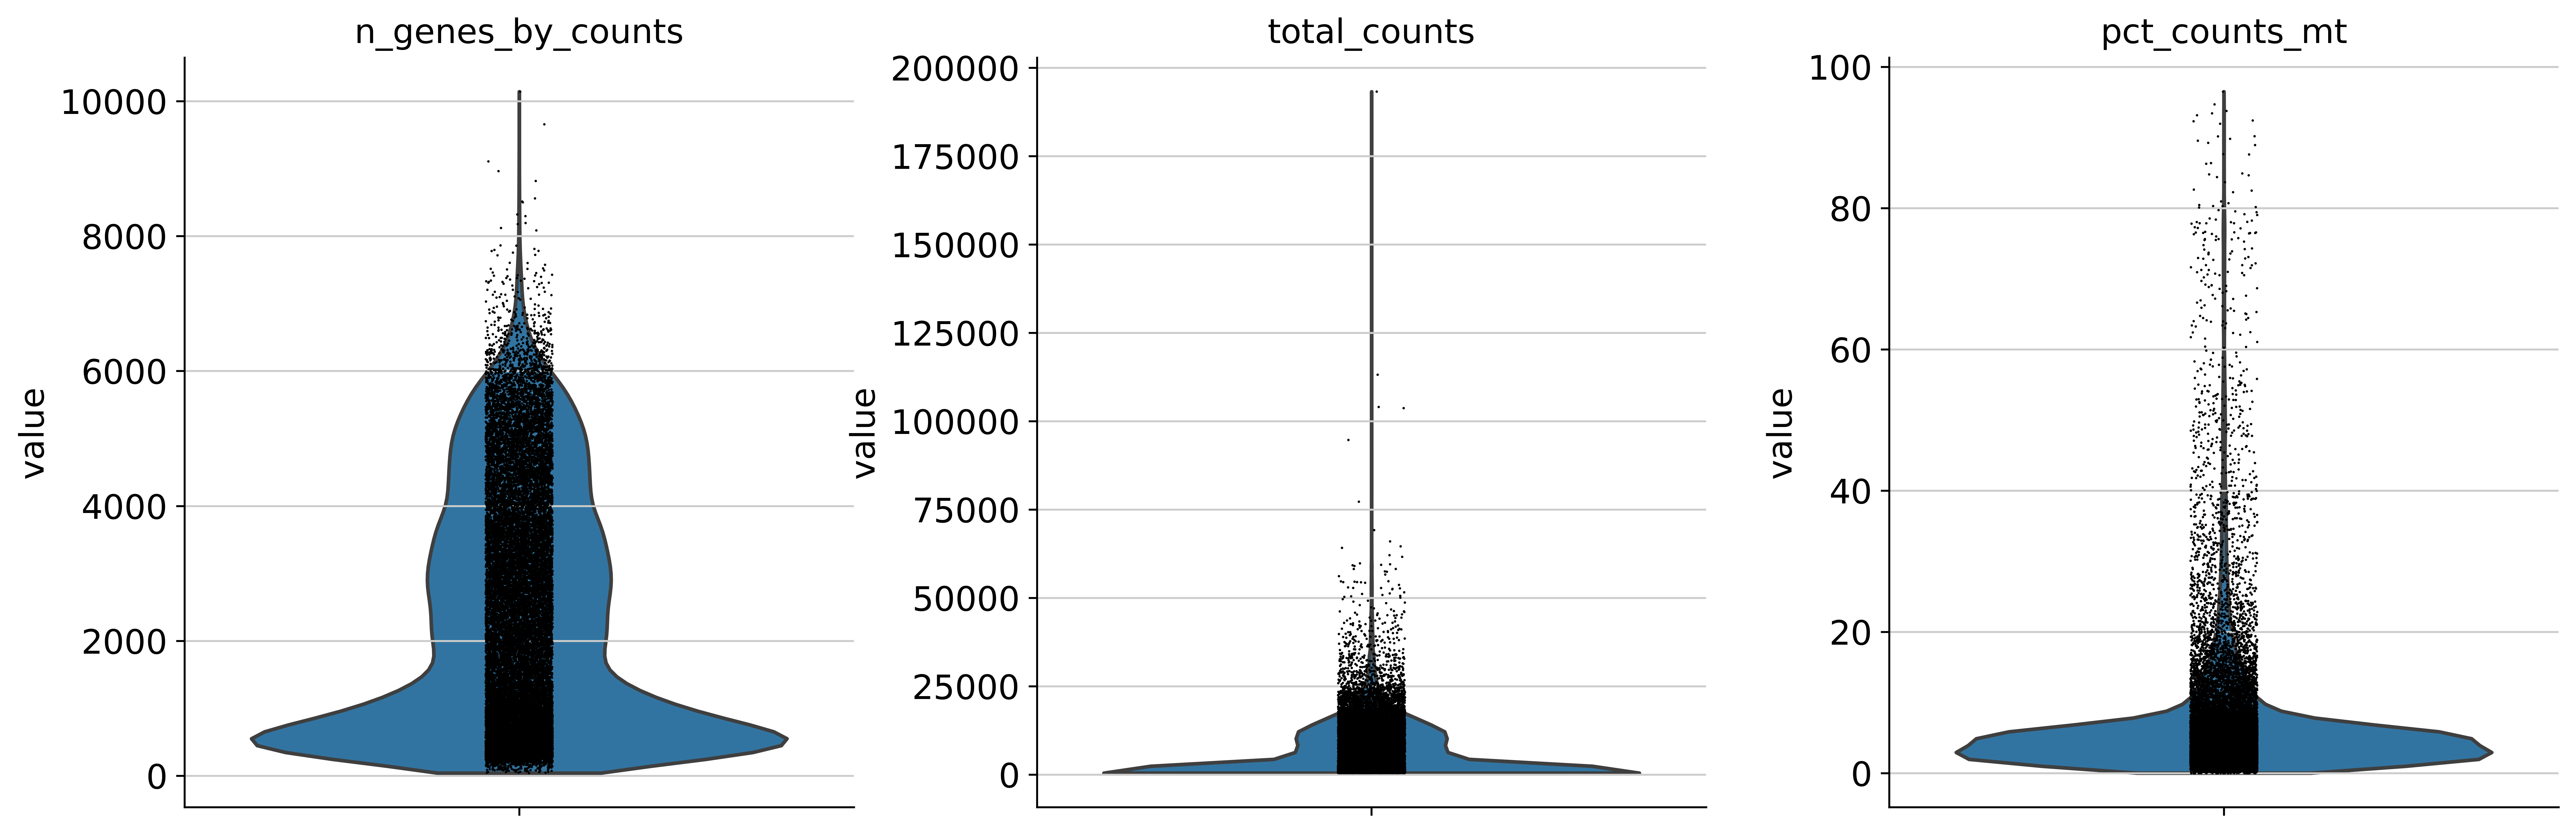

In [22]:
sc.pl.violin(adata_qc, ['n_genes_by_counts', 'total_counts', 'pct_counts_mt'],
             jitter=0.05, multi_panel=True)

n_genes_by_counts


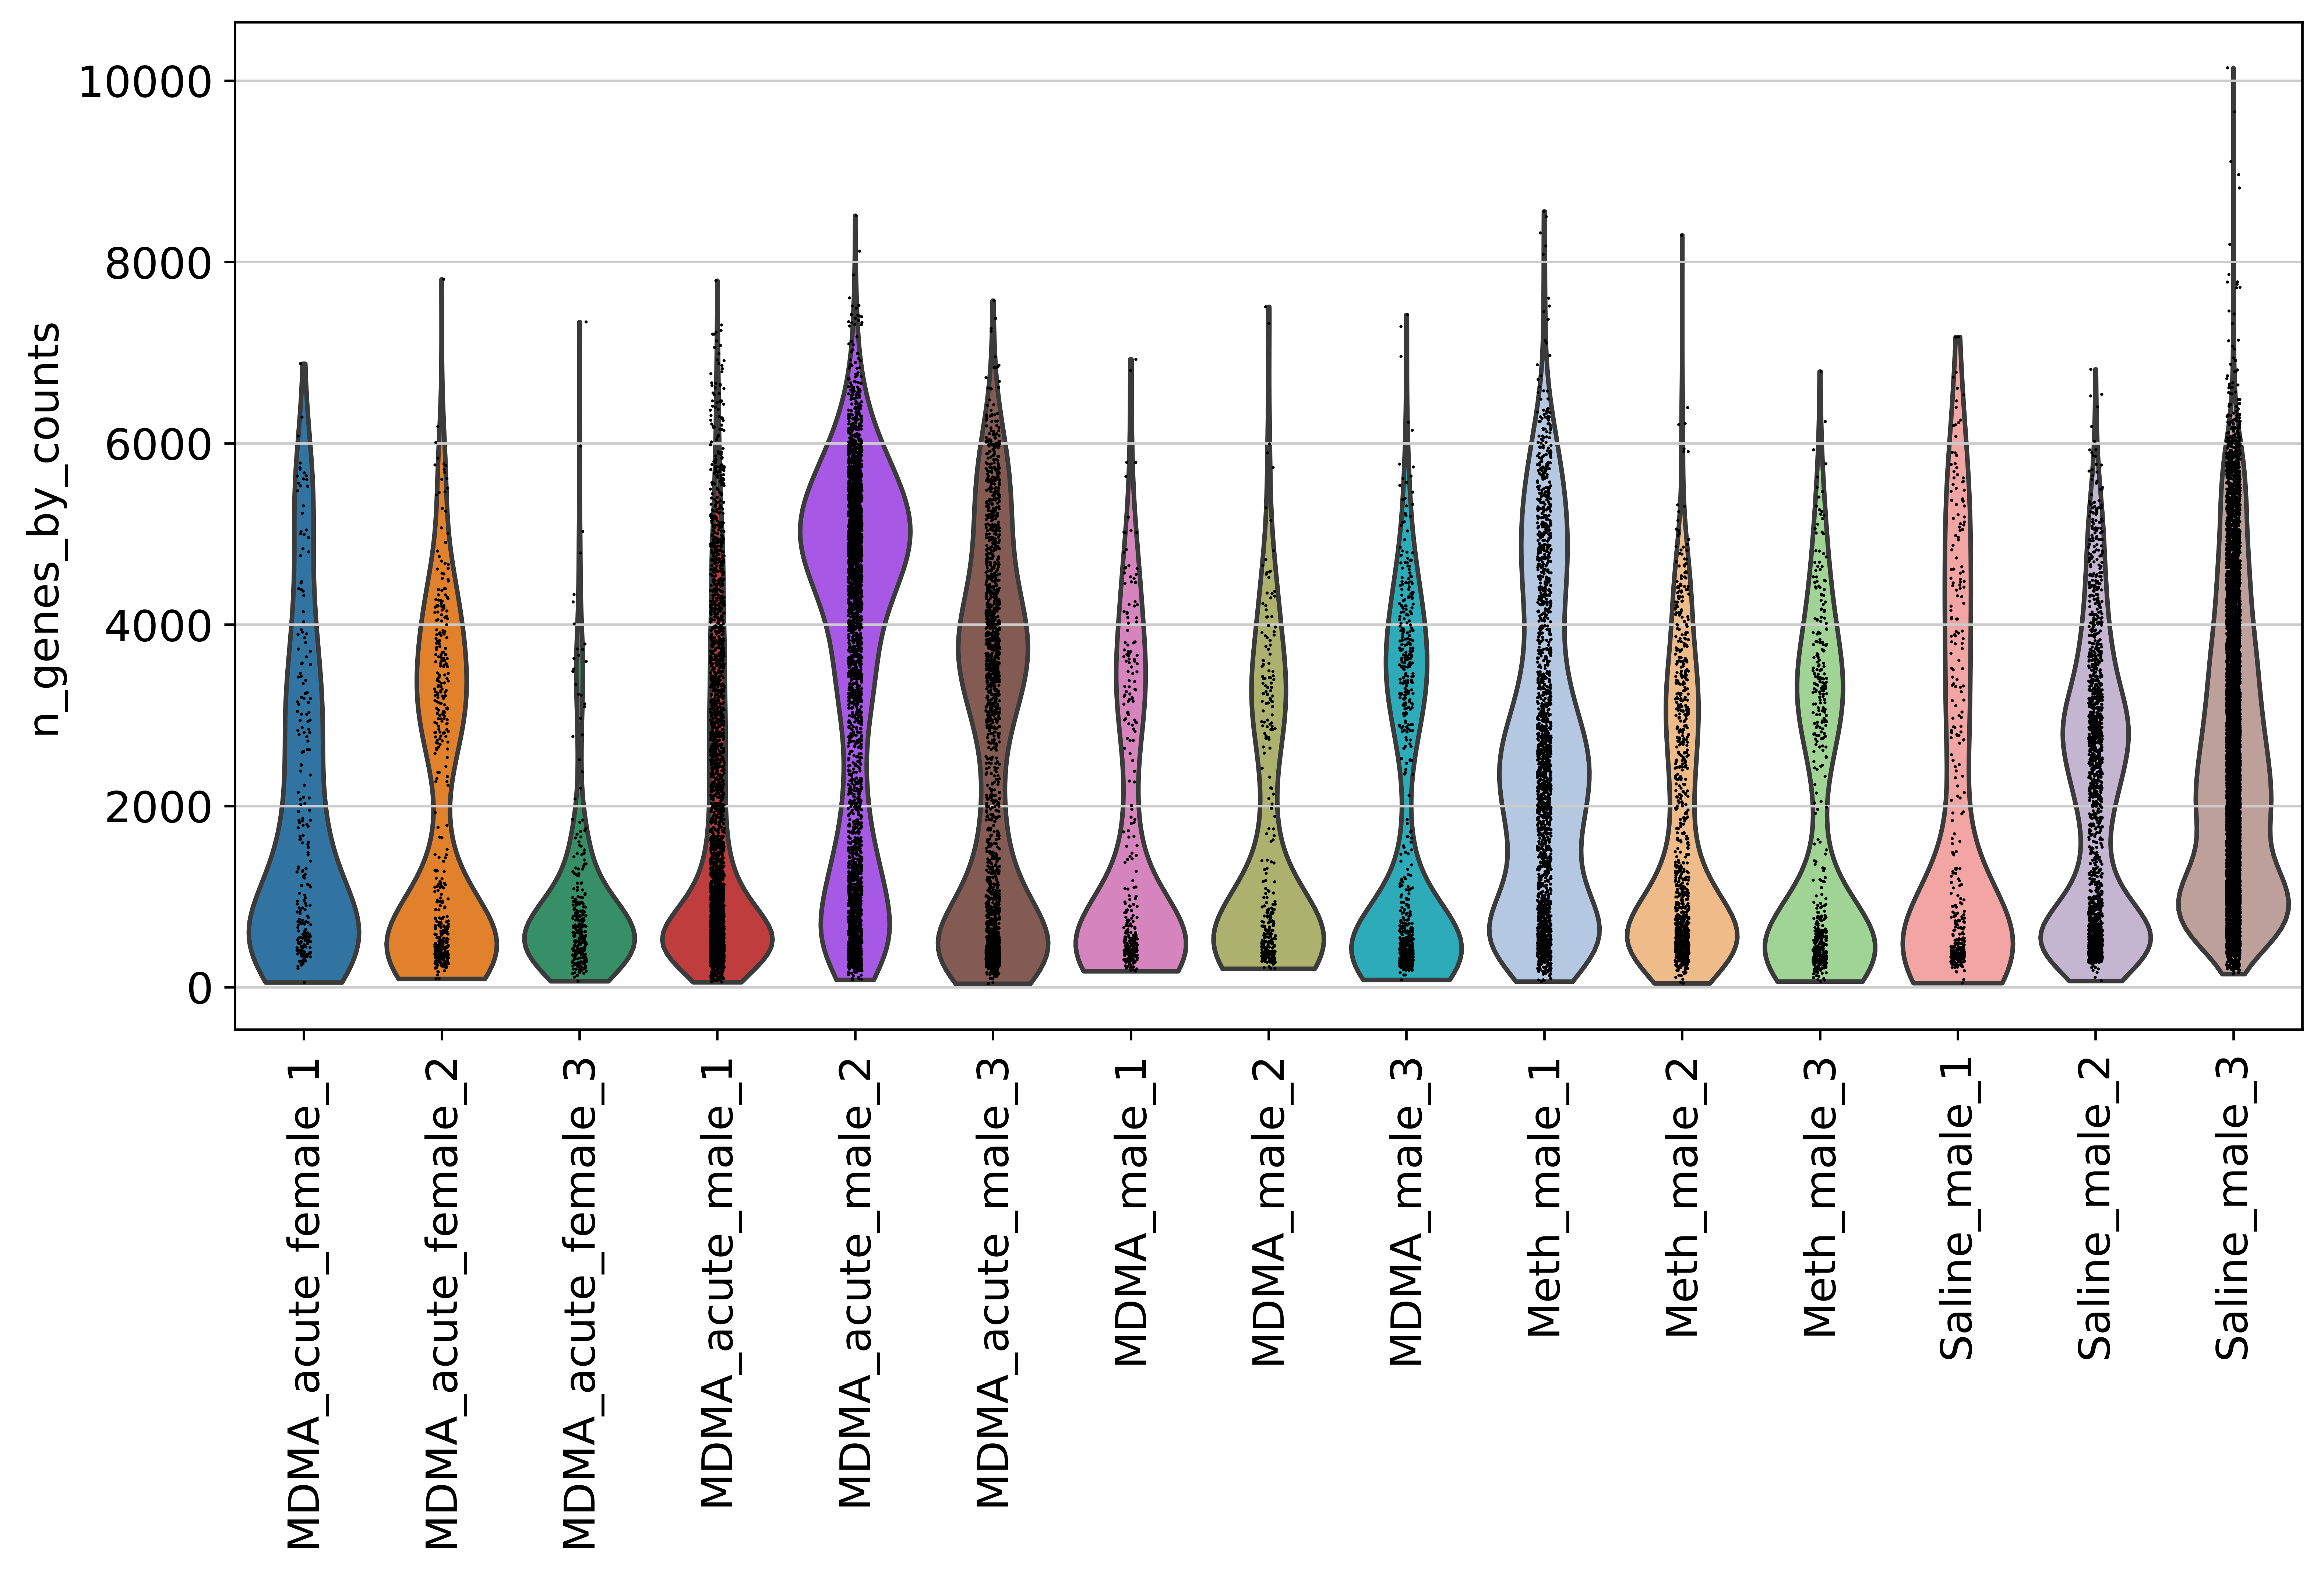

total_counts


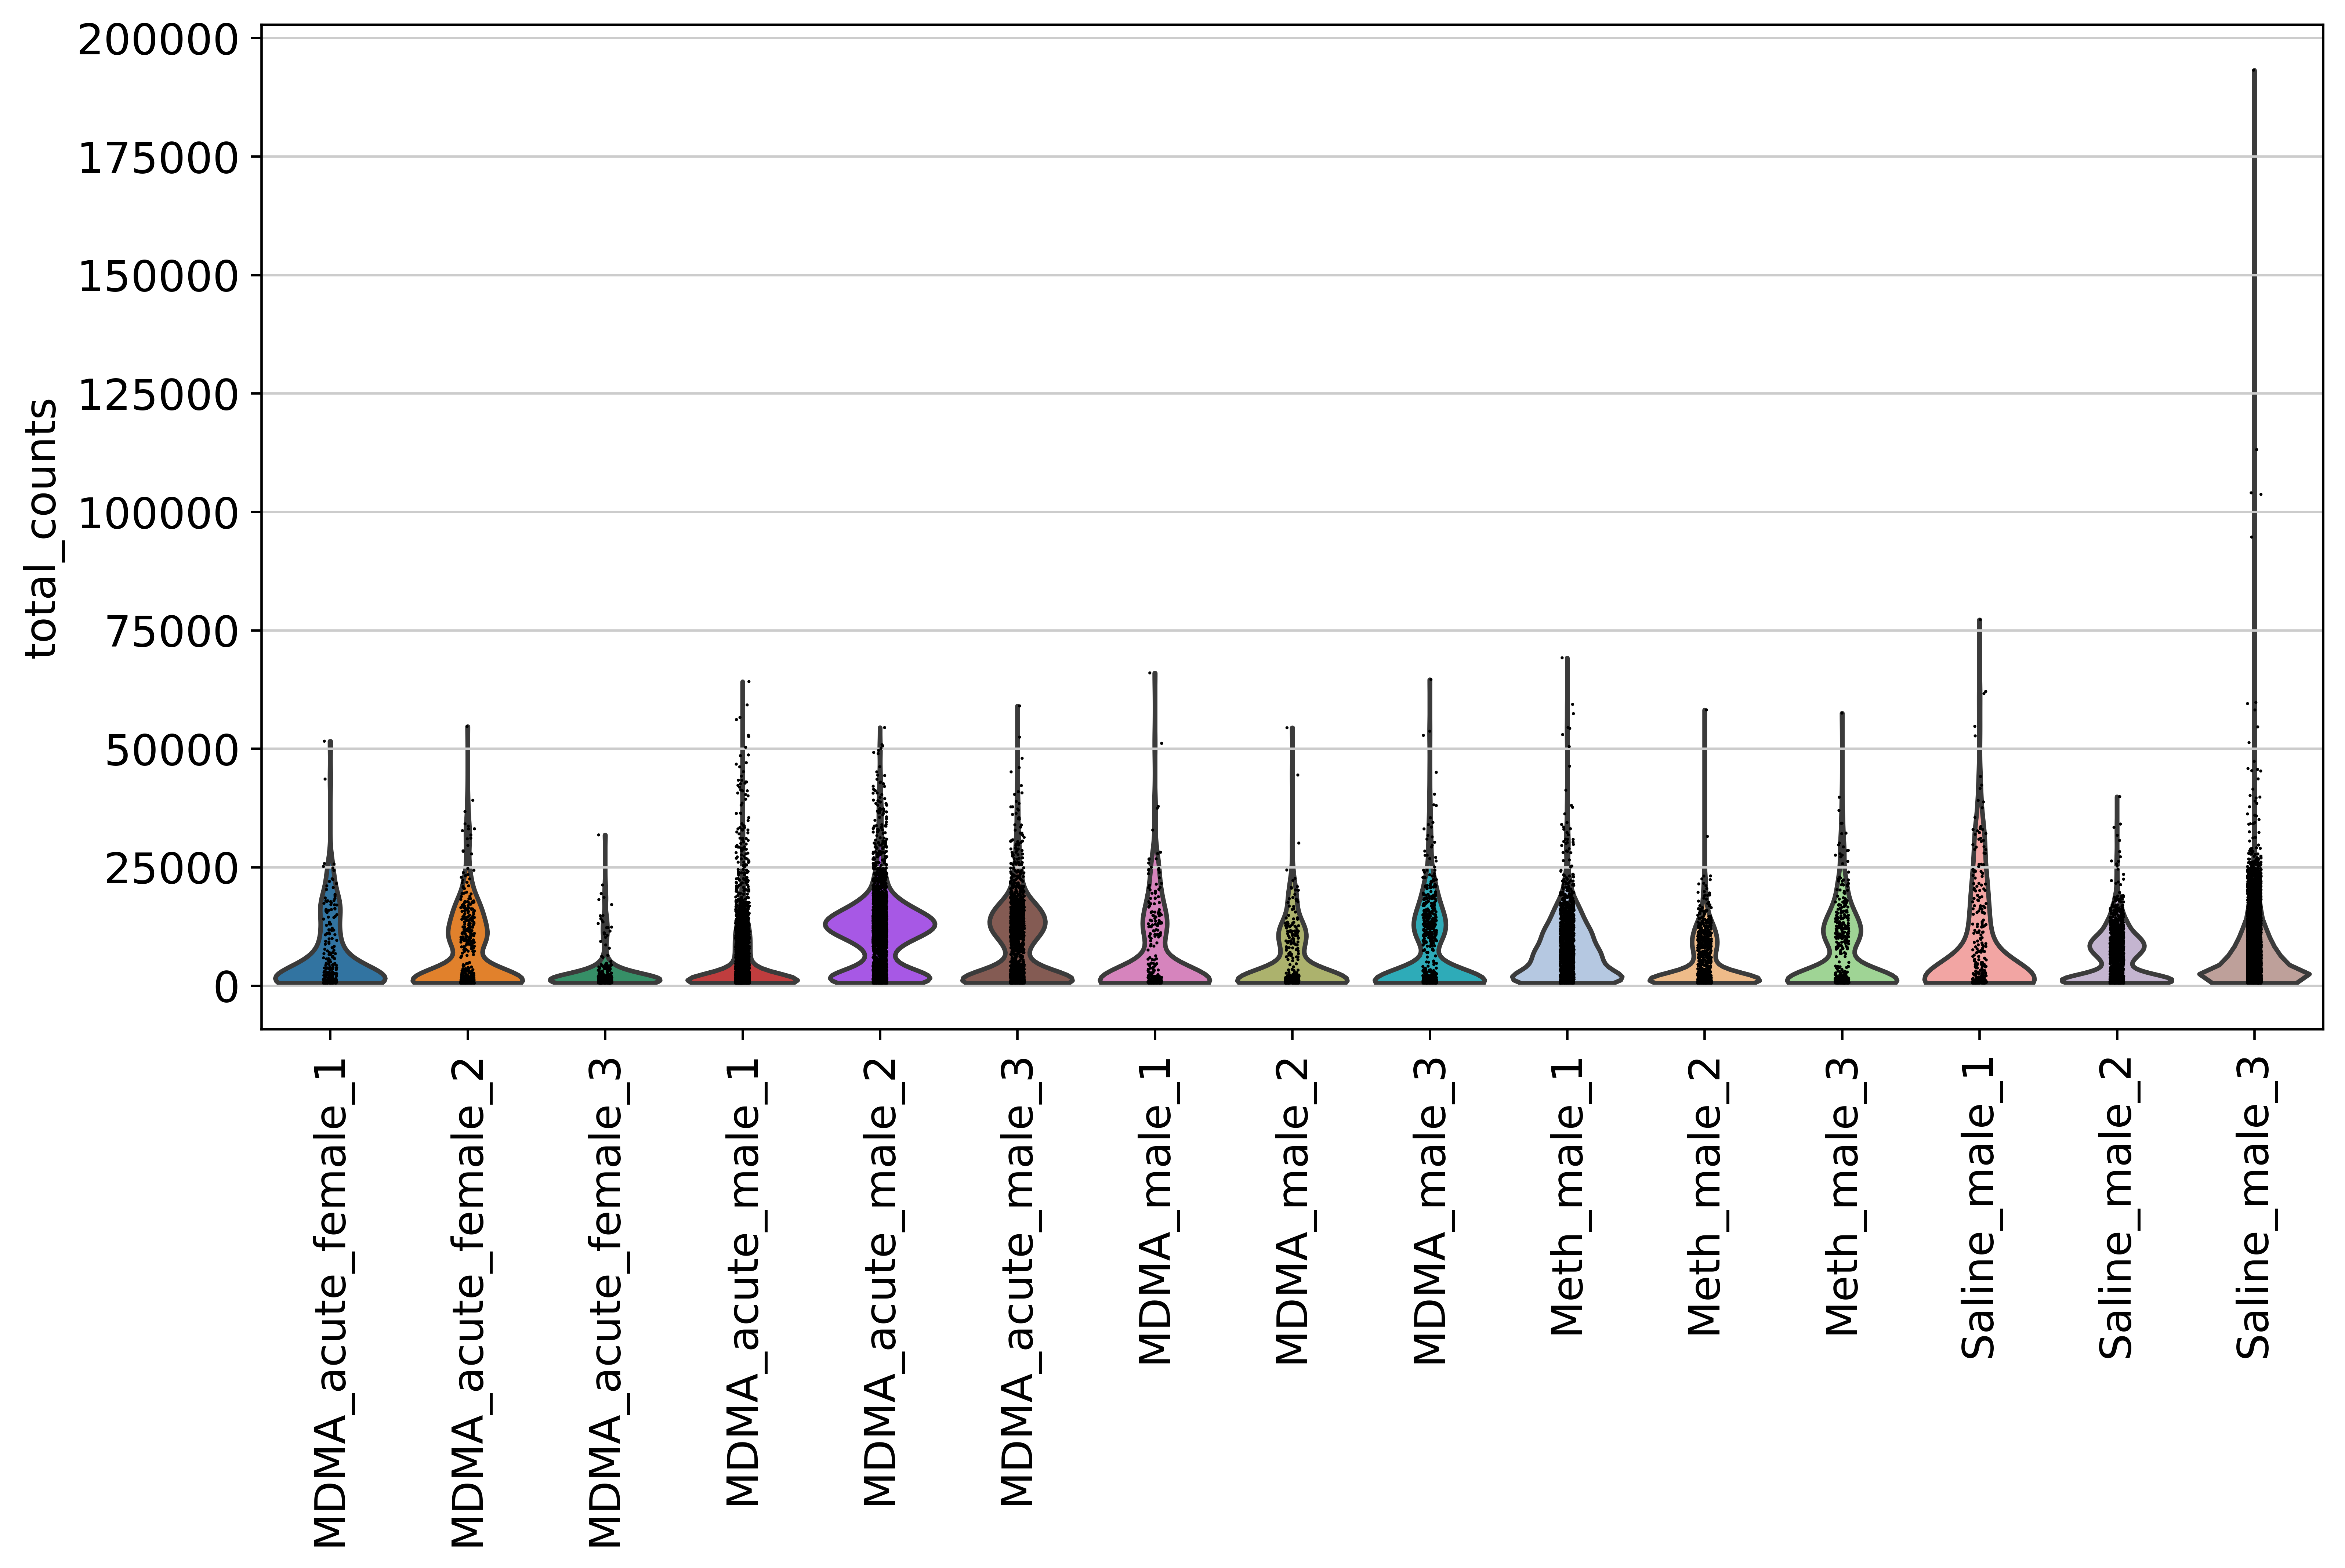

pct_counts_mt


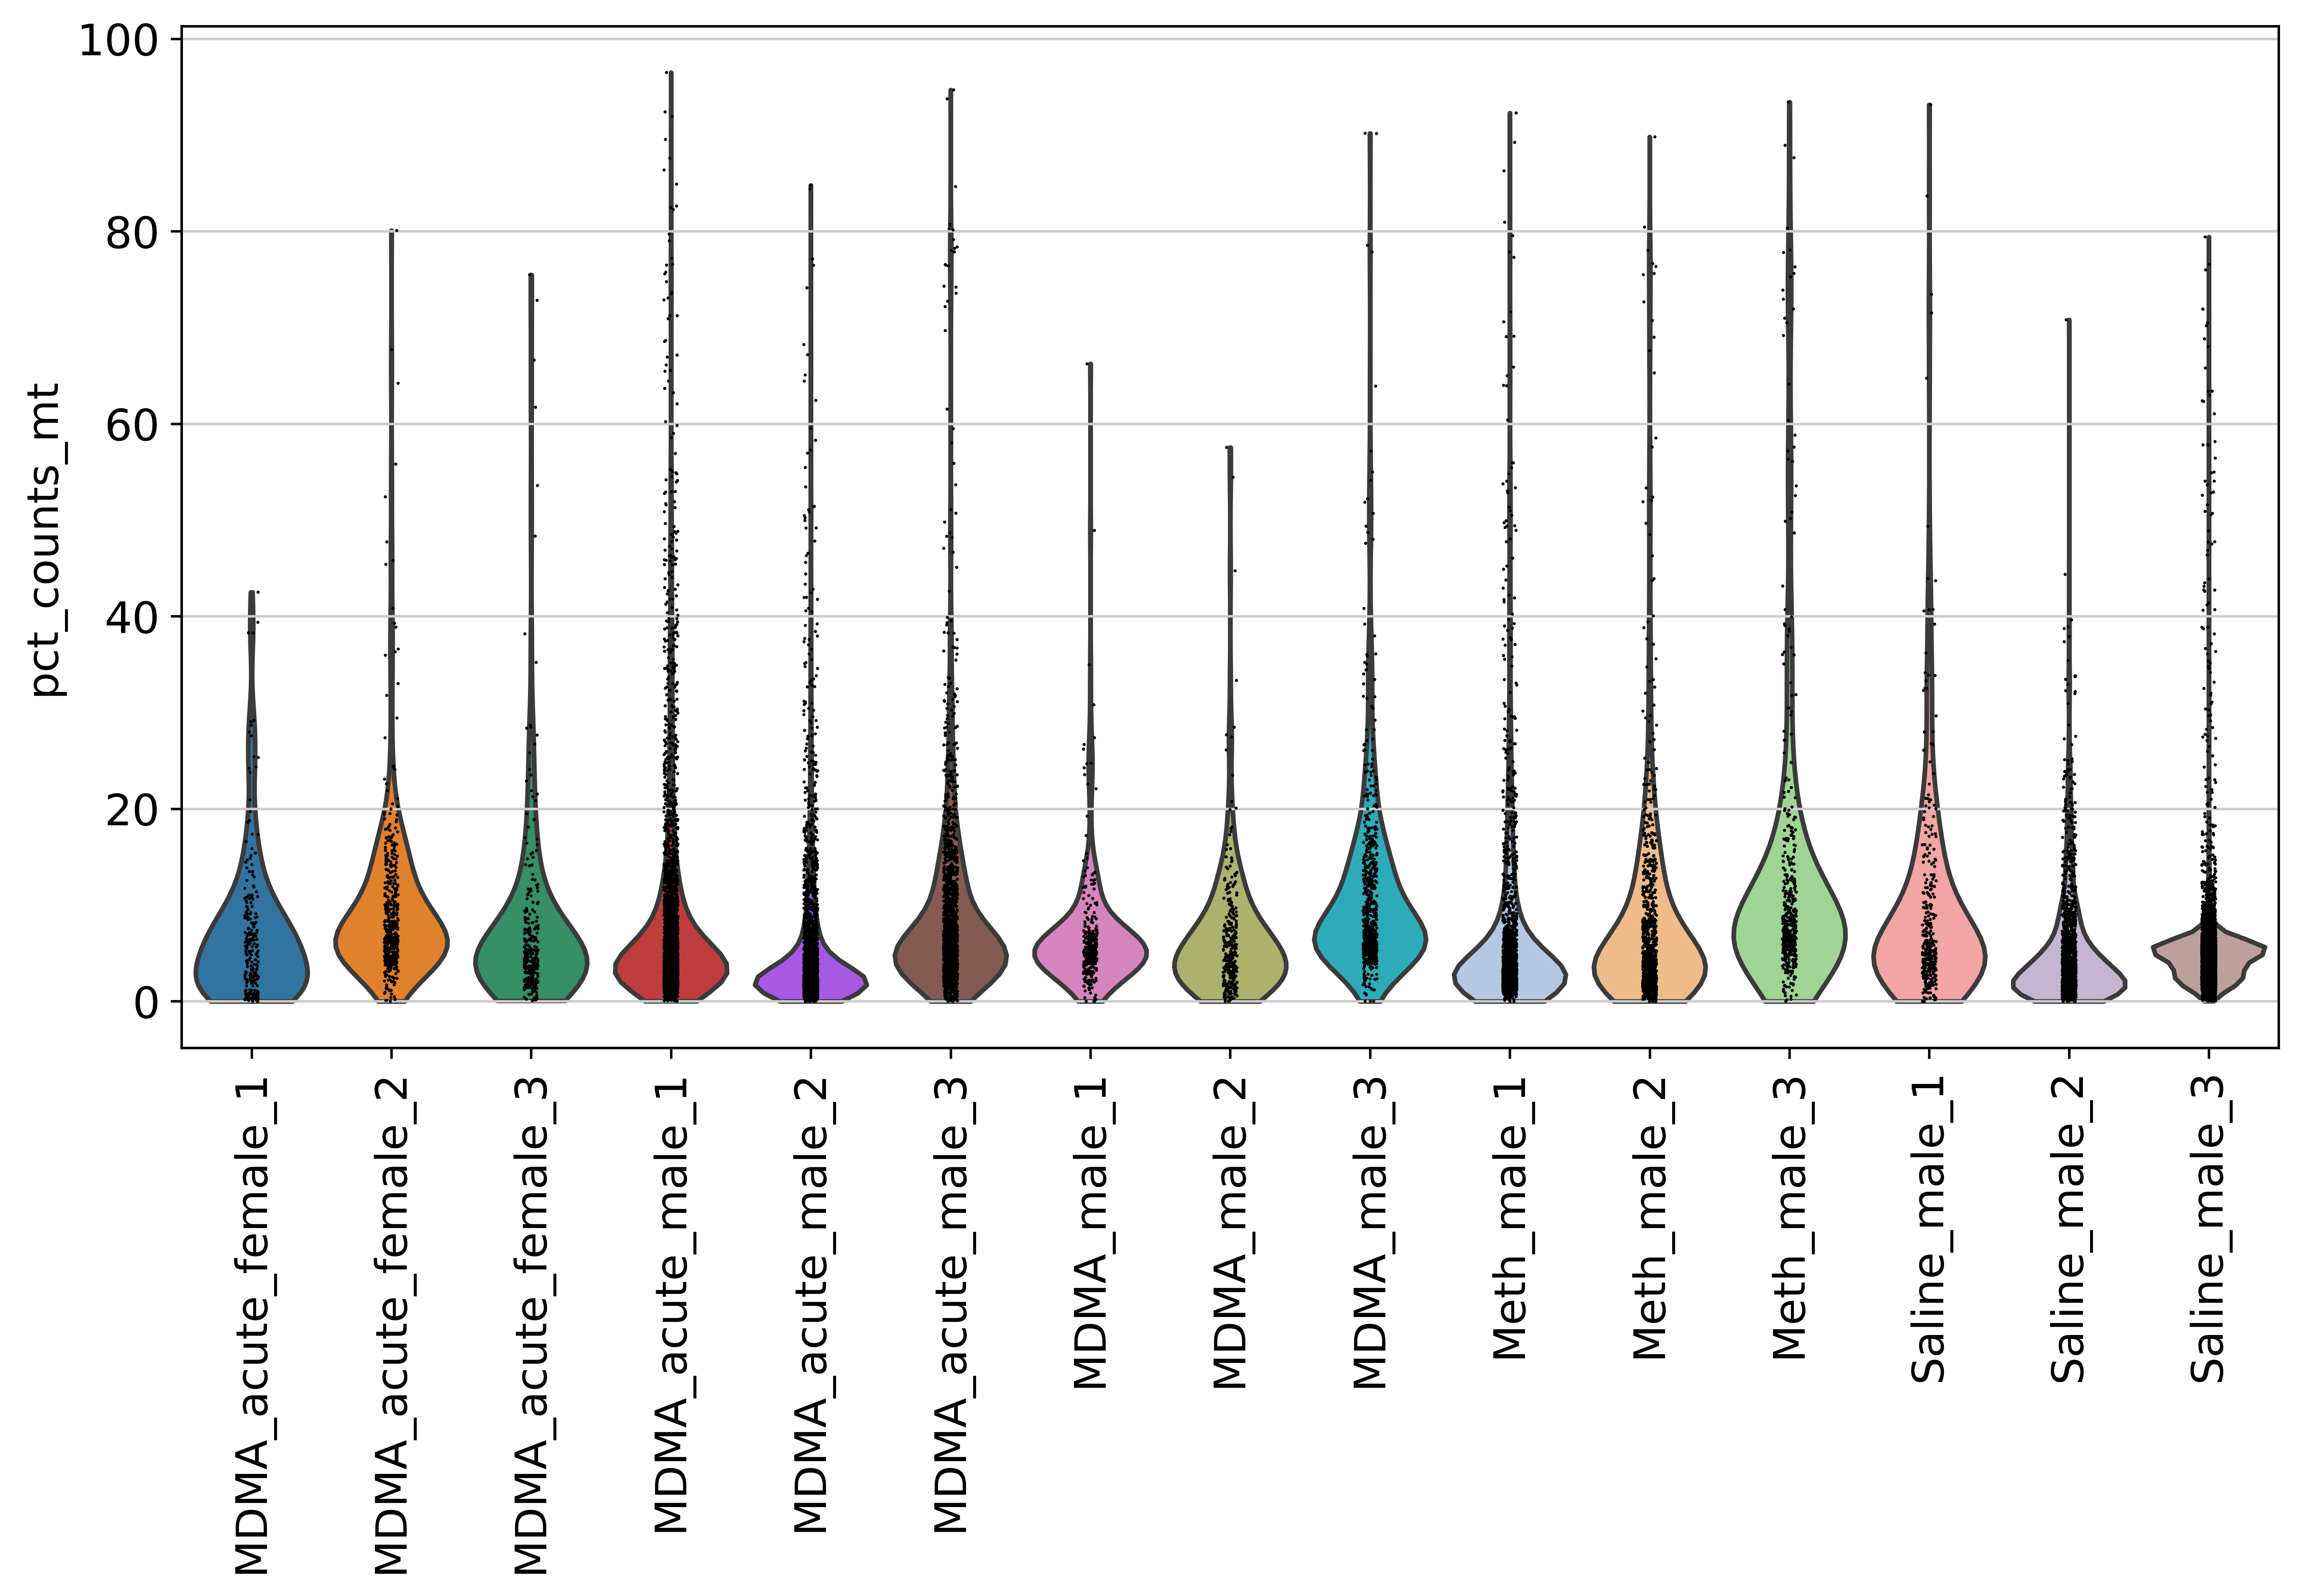

In [23]:
pdf_pages = PdfPages(f'figures/violin_mitochondrial_all.pdf')
for col in [
    'n_genes_by_counts','total_counts',
    'pct_counts_mt'
]:
    # Create a figure instance (ie. a new page)
    fig = plot.figure(figsize=(12, 6), dpi=300)
    # Plot whatever you wish to plot
    print ('\033[1m' + col)
    ax = plt.subplot()
    sc.pl.violin(
        adata_qc, col, jitter=0.05, groupby='batch', 
        multi_panel=True, ax=ax,rotation=90
    )
    # Done with the page
    pdf_pages.savefig(fig,bbox_inches='tight')
# Write the PDF document to the disk
pdf_pages.close()

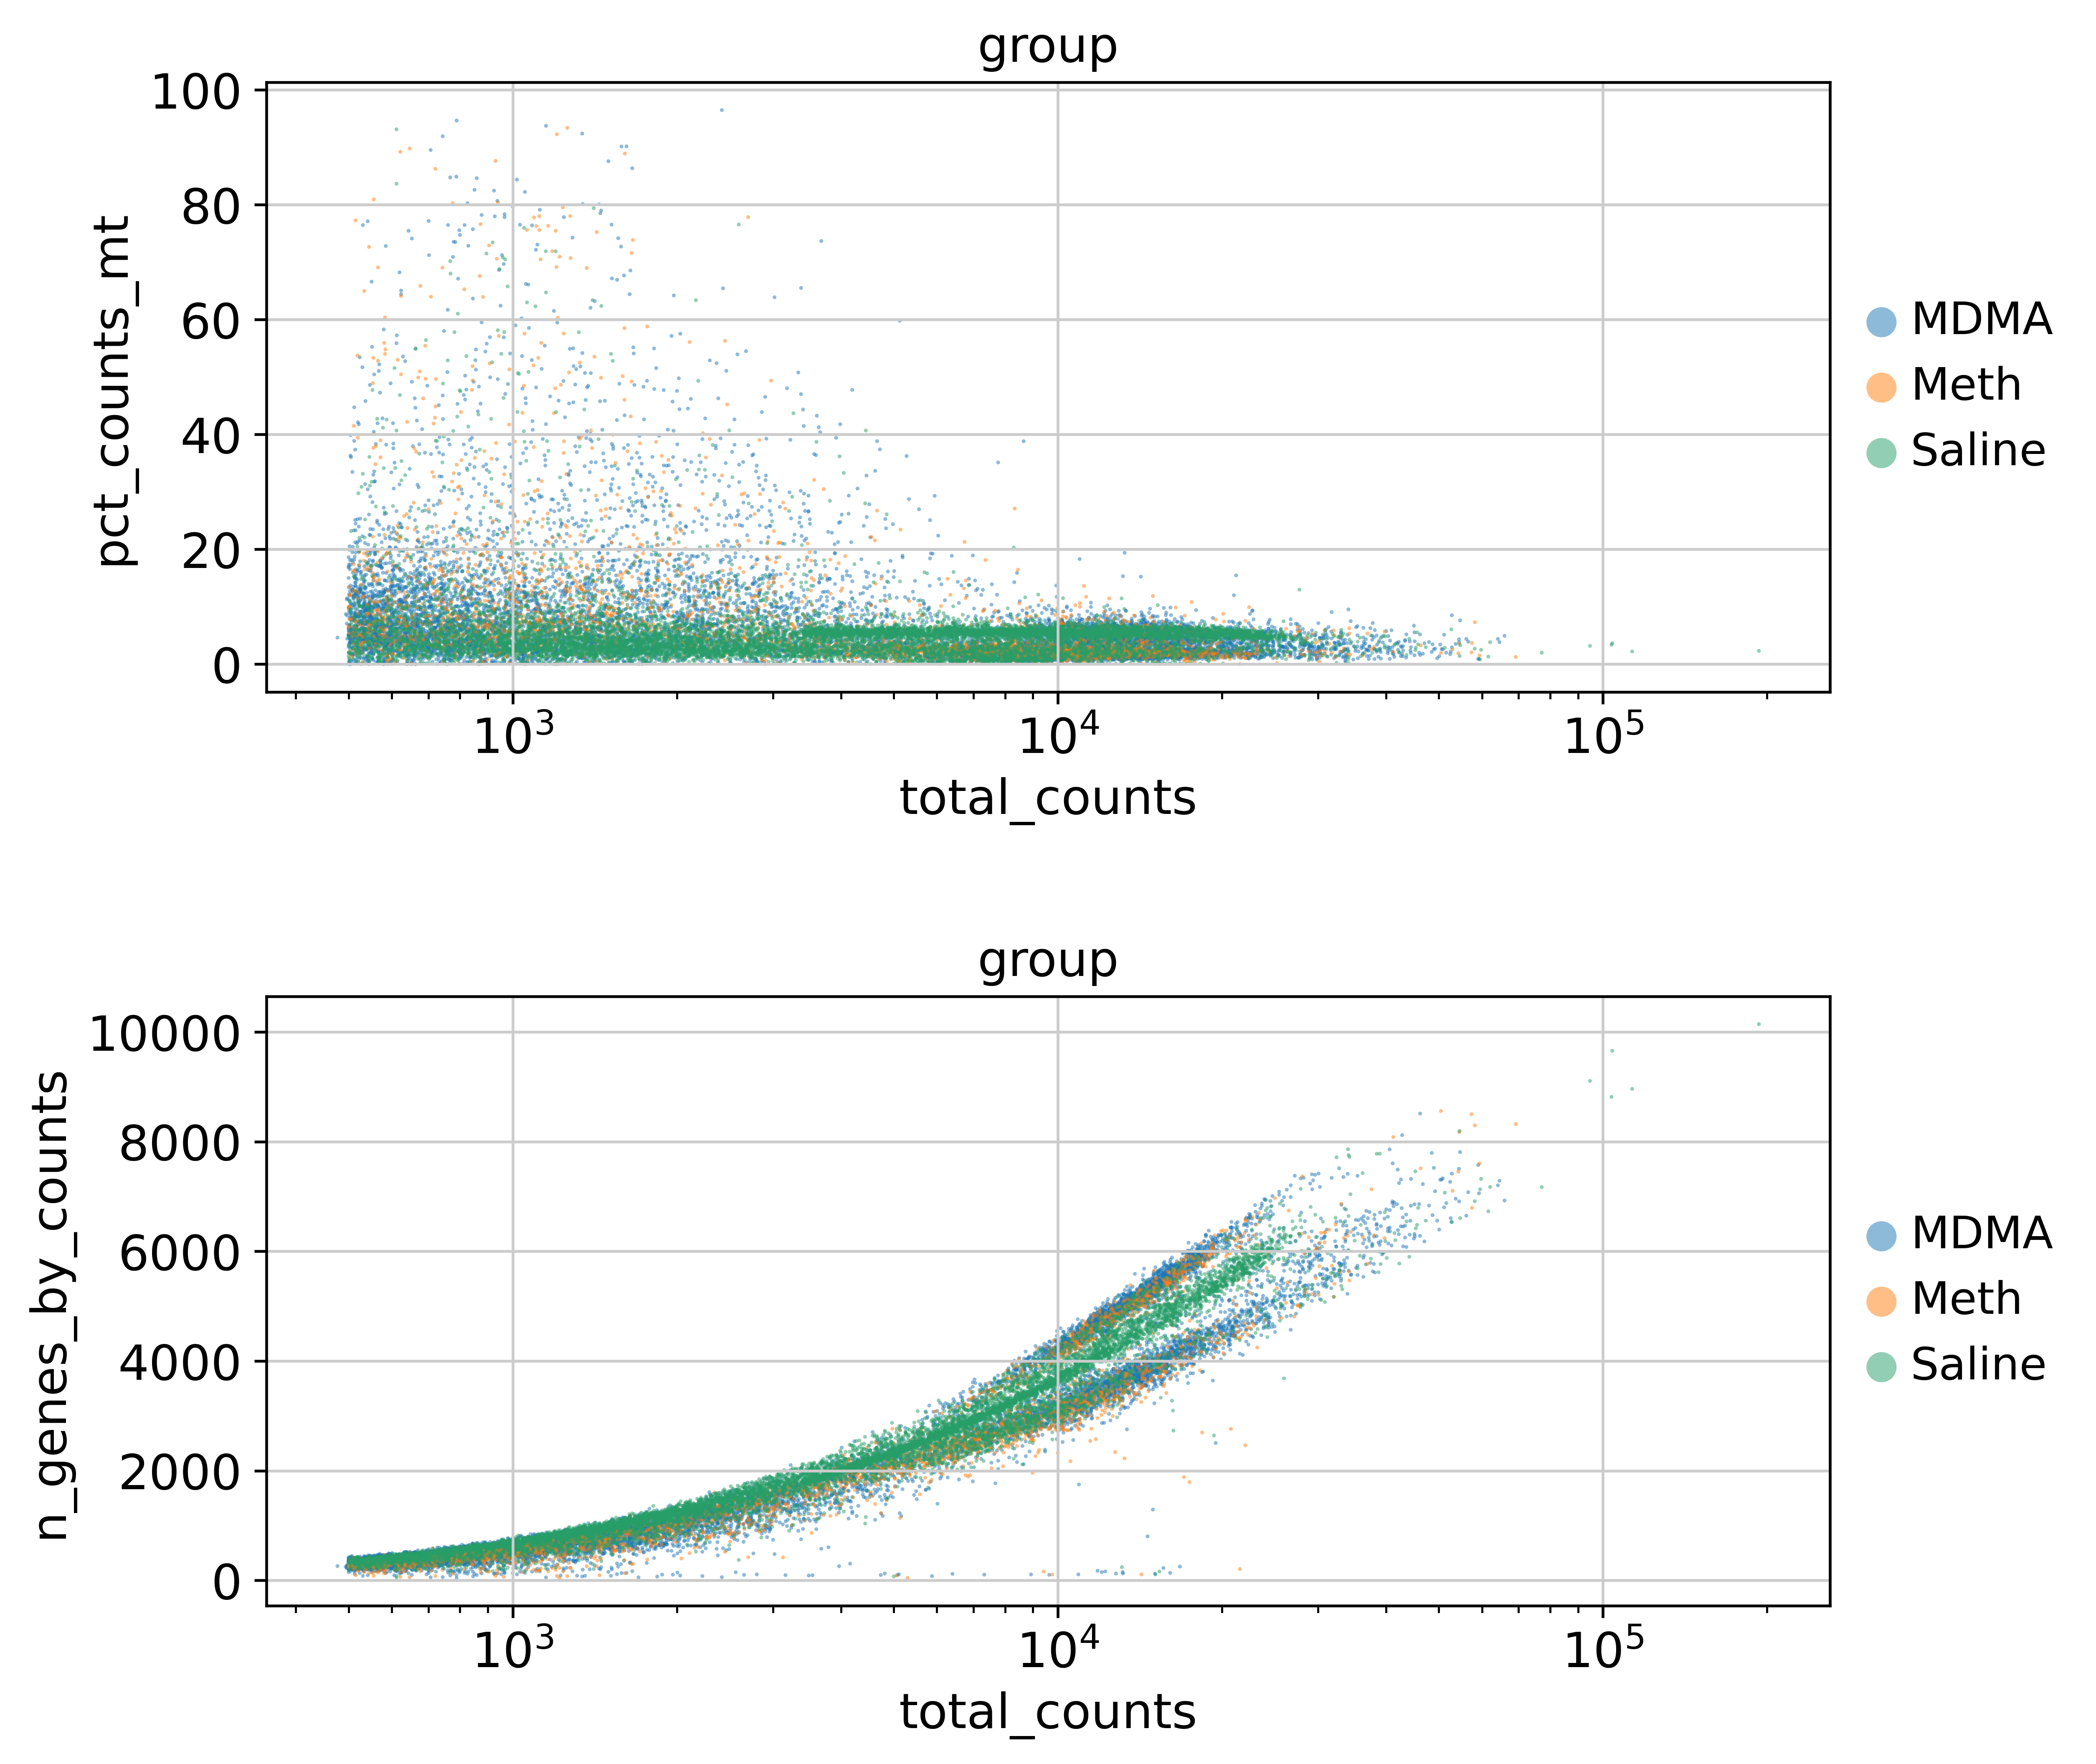

In [24]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8,8), gridspec_kw={'hspace':0.5})

ax1_dict = sc.pl.scatter(
    adata_qc, x='total_counts', y='pct_counts_mt',color='group',ax=ax1, show=False,alpha=0.5
)
ax1.set_xscale('log')

ax2_dict = sc.pl.scatter(
    adata_qc, x='total_counts', color='group', y='n_genes_by_counts',ax=ax2, show=False,alpha=0.5
)
ax2.set_xscale('log')

In [25]:
results_file = 'preprocessing/adatas-qc.h5ad.gz'
adata_qc.write(results_file,compression='gzip')

In [26]:
!ls -s --block-size=M preprocessing/adatas-qc.h5ad.gz

387M preprocessing/adatas-qc.h5ad.gz


### Filtering

In [61]:
adata1 = adata_qc.copy()

Observation names are not unique. To make them unique, call `.obs_names_make_unique`.


#### Basic filtering

In [62]:
adata1.layers["counts"] = adata1.X.copy()

In [63]:
min_genes=150
min_cells=3

In [64]:
print(f'Before:\n\t{adata1.shape[0]} cells, {adata1.shape[1]} genes')
# Basic filtering:
sc.pp.filter_cells(adata1, min_genes=min_genes)
sc.pp.filter_genes(adata1, min_cells=min_cells)

print(f'After:\n\t{adata1.shape[0]} cells, {adata1.shape[1]} genes')

Before:
	24816 cells, 32285 genes


Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
Observation names are not unique. To make them unique, call `.obs_names_make_unique`.


After:
	24713 cells, 22615 genes


___
Remove cells that have too many mitochondrial genes expressed or too many total counts:


In [65]:
n_mt = 20
n_cnt = 6000

# filter based on MT counts % 
keep = adata_qc.obs.pct_counts_mt < n_mt

mt_df = pd.concat([
    adata_qc.obs.groupby('cond').size(),
    adata_qc[keep].obs.groupby('cond').size()
],axis=1).rename(columns={0:'before',1:'after'})



# filter based on n_genes_by_counts
keep = adata_qc.obs.n_genes_by_counts < n_cnt

cnt_df = pd.concat([
    adata_qc.obs.groupby('cond').size(),
    adata_qc[keep].obs.groupby('cond').size()
],axis=1).rename(columns={0:'before',1:'after'})

In [66]:
pd.concat([mt_df.before - mt_df.after, cnt_df.before - cnt_df.after],axis=1).rename(columns={0:'mt',1:'cnt'})

,mt,cnt
cond,,
MDMA_acute_female,63,7
MDMA_acute_male,585,327
MDMA_male,100,9
Meth_male,257,66
Saline_male,189,145


Actual filtering!

In [67]:
t0 = adata1.shape[0]

adata1 = adata1[
    (adata1.obs.n_genes_by_counts < n_cnt) & 
    (adata1.obs.pct_counts_mt < n_mt),:
]

t1 = adata1.shape[0]
print (f'`filter mt and cnt` -> from #{t0} cells filter #{t0-t1}!')

`filter mt and cnt` -> from #24713 cells filter #1693!


#### Remove doublet

- https://github.com/swolock/scrublet/blob/master/examples/scrublet_basics.ipynb

<!-- > #### Plot doublet score histograms for observed transcriptomes and simulated doublets
The simulated doublet histogram is typically bimodal. The left mode corresponds to "embedded" doublets generated by two cells with similar gene expression. The right mode corresponds to "neotypic" doublets, which are generated by cells with distinct gene expression (e.g., different cell types) and are expected to introduce more artifacts in downstream analyses. Scrublet can only detect neotypic doublets.

> To call doublets vs. singlets, we must set a threshold doublet score, ideally at the minimum between the two modes of the simulated doublet histogram. `scrub_doublets()` attempts to identify this point automatically and has done a good job in this example. However, if automatic threshold detection doesn't work well, you can adjust the threshold with the `call_doublets()` function. For example: -->

In [68]:
adata_scr = adata1.copy()

Observation names are not unique. To make them unique, call `.obs_names_make_unique`.


In [69]:
adata_scr.obs_names_make_unique()

In [70]:
sce.pp.scrublet(adata_scr,batch_key='batch')

Trying to set attribute `.var` of view, copying.
/data_gilbert/home/aarab/anaconda3/envs/sc-analysis/lib/python3.9/site-packages/scanpy/preprocessing/_normalization.py:170: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)
Trying to set attribute `.var` of view, copying.


Automatically set threshold at doublet score = 0.20
Detected doublet rate = 1.3%
Estimated detectable doublet fraction = 15.6%
Overall doublet rate:
	Expected   = 5.0%
	Estimated  = 8.5%


/data_gilbert/home/aarab/anaconda3/envs/sc-analysis/lib/python3.9/site-packages/scanpy/preprocessing/_normalization.py:170: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)
Trying to set attribute `.var` of view, copying.


Automatically set threshold at doublet score = 0.26
Detected doublet rate = 0.7%
Estimated detectable doublet fraction = 4.2%
Overall doublet rate:
	Expected   = 5.0%
	Estimated  = 16.2%


/data_gilbert/home/aarab/anaconda3/envs/sc-analysis/lib/python3.9/site-packages/scanpy/preprocessing/_normalization.py:170: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


Automatically set threshold at doublet score = 0.20
Detected doublet rate = 0.7%
Estimated detectable doublet fraction = 7.0%
Overall doublet rate:
	Expected   = 5.0%
	Estimated  = 10.5%


... (20 outputs left out)

Trying to set attribute `.var` of view, copying.
/data_gilbert/home/aarab/anaconda3/envs/sc-analysis/lib/python3.9/site-packages/scanpy/preprocessing/_normalization.py:170: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


Automatically set threshold at doublet score = 0.27
Detected doublet rate = 0.9%
Estimated detectable doublet fraction = 35.6%
Overall doublet rate:
	Expected   = 5.0%
	Estimated  = 2.4%


Trying to set attribute `.var` of view, copying.
/data_gilbert/home/aarab/anaconda3/envs/sc-analysis/lib/python3.9/site-packages/scanpy/preprocessing/_normalization.py:170: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


Automatically set threshold at doublet score = 0.59
Detected doublet rate = 0.1%
Estimated detectable doublet fraction = 3.8%
Overall doublet rate:
	Expected   = 5.0%
	Estimated  = 1.6%


In [71]:
scr_thr = []
for k in adata_scr.uns['scrublet']['batches']:
    scr_thr.append((k,adata_scr.uns['scrublet']['batches'][k]['threshold']))

In [72]:
adata_scr.obs.groupby(['group','predicted_doublet']).size()

group   predicted_doublet
MDMA    False                10130
        True                    41
Meth    False                 2901
        True                    17
Saline  False                 9912
        True                    19
dtype: int64

In [73]:
results_file = 'preprocessing/adatas-scr.h5ad.gz'
adata_scr.write(results_file,compression='gzip')

/data_gilbert/home/aarab/anaconda3/envs/sc-analysis/lib/python3.9/site-packages/anndata/_core/anndata.py:1220: FutureWarning: The `inplace` parameter in pandas.Categorical.reorder_categories is deprecated and will be removed in a future version. Removing unused categories will always return a new Categorical object.
  c.reorder_categories(natsorted(c.categories), inplace=True)
... storing 'batch' as categorical
/data_gilbert/home/aarab/anaconda3/envs/sc-analysis/lib/python3.9/site-packages/anndata/_core/anndata.py:1220: FutureWarning: The `inplace` parameter in pandas.Categorical.reorder_categories is deprecated and will be removed in a future version. Removing unused categories will always return a new Categorical object.
  c.reorder_categories(natsorted(c.categories), inplace=True)
... storing 'cond' as categorical
/data_gilbert/home/aarab/anaconda3/envs/sc-analysis/lib/python3.9/site-packages/anndata/_core/anndata.py:1220: FutureWarning: The `inplace` parameter in pandas.Categorical

In [74]:
results_file = 'preprocessing/adatas-scr.h5ad.gz'

adata_scr = sc.read_h5ad(results_file)

___

In [75]:
# remove doublet
adata2 = adata1[~adata_scr.obs.predicted_doublet]

## Save pre-processed data 

In [76]:
adata3 = adata2.copy()

Observation names are not unique. To make them unique, call `.obs_names_make_unique`.


In [78]:
adata3.obs = adata3.obs[['batch','cond','group']]

del adata3.var 
del adata3.uns

In [79]:
adata3

AnnData object with n_obs × n_vars = 22943 × 22615
    obs: 'batch', 'cond', 'group'
    layers: 'counts'

In [80]:
results_file = 'preprocessing/adatas-merge-reps-clean-v2.h5ad.gz'
adata3.write(results_file,compression='gzip')

####

In [ ]:
# writer = pd.ExcelWriter('preprocessing/cell-counts.xlsx', engine='xlsxwriter')

# # Write each dataframe to a different worksheet.
# cnt_df.to_excel(writer,sheet_name='high count filtering')

# pd.concat([
#     adata.obs.groupby('batch').size(),
#     adata_flt_mt.obs.groupby('batch').size(),
#     adata_flt_dd.obs.groupby('batch').size()
# ],axis=1).rename(columns={
#     0:'raw',1:'mt filtering',2:'doublet filtering'
# }).to_excel(writer,sheet_name='batches')

# # Close the Pandas Excel writer and output the Excel file.
# writer.save()

# 
<!-- Wed Apr 27 15:50:17 PDT 2022 -->

In [81]:
!ls -s --block-size=M preprocessing/adatas-*.h5ad.gz

726M preprocessing/adatas-hvar.h5ad.gz
254M preprocessing/adatas-merge-reps-clean.h5ad.gz
258M preprocessing/adatas-merge-reps-clean-v2.h5ad.gz
131M preprocessing/adatas-qc.h5ad.gz
272M preprocessing/adatas-scr.h5ad.gz


In [82]:
!date

Sun Jul 10 17:49:06 PDT 2022
